<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week08/car_evaluation_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Car Evaluation — 딥러닝 다중 분류


## 1. Google Drive 연결 및 데이터 불러오기

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import io
import zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

zip_path = '/content/drive/MyDrive/Colab Notebooks/car+evaluation (1).zip'
columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
with zipfile.ZipFile(zip_path) as z:
    with z.open('car.data') as f:
        df = pd.read_csv(f, header=None, names=columns)
print(df.shape)
display(df.head())
print(df['class'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


## 2. X/y 분리 및 원-핫 인코딩
입력 특성 6개도 문자열 범주형이므로 원핫 인코딩한다. 정답도 원핫 인코딩하여 `categorical_crossentropy`와 맞춘다.

In [3]:
X = pd.get_dummies(df.drop(columns='class'), dtype='float32')
class_names = ['unacc', 'acc', 'good', 'vgood']
y = pd.get_dummies(df['class'], dtype='float32').reindex(columns=class_names, fill_value=0)
print('X shape:', X.shape)
print('y shape:', y.shape)
display(y.head())

X shape: (1728, 21)
y shape: (1728, 4)


,unacc,acc,good,vgood
0,1.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0


## 3. 학습/테스트 분리

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy(), y.to_numpy(), test_size=0.2, random_state=42,
    stratify=df['class']
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1382, 21) (346, 21) (1382, 4) (346, 4)


## 4. 딥러닝 모델 생성 및 컴파일
출력층 4개 뉴런, `softmax`; 손실 함수 `categorical_crossentropy`.

In [5]:
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,300 (5.08 KB)

 Trainable params: 1,300 (5.08 KB)

 Non-trainable params: 0 (0.00 B)

## 5. 학습

In [6]:
history = model.fit(
    X_train, y_train,
    epochs=100, batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5303 - loss: 1.2043 - val_accuracy: 0.6968 - val_loss: 1.0337
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7158 - loss: 0.8699 - val_accuracy: 0.6931 - val_loss: 0.7952
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7167 - loss: 0.6797 - val_accuracy: 0.7112 - val_loss: 0.6749
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7819 - loss: 0.5533 - val_accuracy: 0.7690 - val_loss: 0.5660
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8362 - loss: 0.4543 - val_accuracy: 0.8123 - val_loss: 0.4860
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8643 - loss: 0.3832 - val_accuracy: 0.8303 - val_loss: 0.4262
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8805 - loss: 0.3317 - val_accuracy: 0.8448 - val_loss: 0.3825
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8851 - loss: 0.2925 - val_accuracy: 0.8592 - v

## 6. 테스트 데이터 평가

In [7]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Test loss: 0.0113
Test accuracy: 0.9971


## 7. 학습 곡선

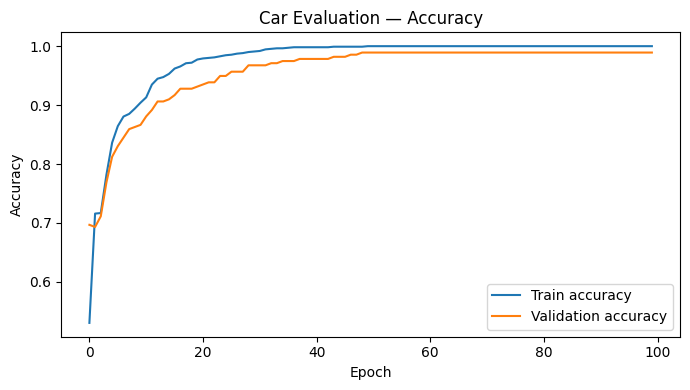

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Car Evaluation — Accuracy')
plt.legend(); plt.tight_layout(); plt.show()

## 8. 분류 결과 및 혼동행렬

              precision    recall  f1-score   support

       unacc       1.00      1.00      1.00       242
         acc       0.99      1.00      0.99        77
        good       1.00      0.93      0.96        14
       vgood       1.00      1.00      1.00        13

    accuracy                           1.00       346
   macro avg       1.00      0.98      0.99       346
weighted avg       1.00      1.00      1.00       346



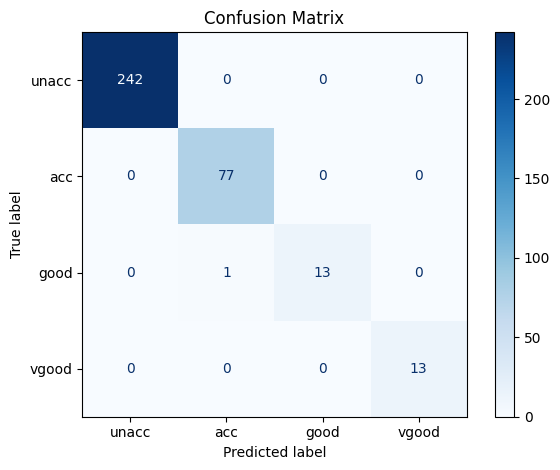

In [9]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(prob, axis=1)
y_true = np.argmax(y_test, axis=1)
print(classification_report(y_true, y_pred, labels=range(4), target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=range(4), display_labels=class_names, cmap='Blues')
plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

클래스 분포가 불균형하므로 accuracy뿐 아니라 클래스별 precision, recall, F1-score도 함께 확인한다.